# 1주차 · 관찰을 읽고 예측하기

## 하나의 질문으로 시작합니다

**일주일 동안의 기록과 잎 관찰이 있는 화분에서, 아직 재지 않은 높이를 어떻게 예상하고 확인할까요?** 한 행의 뜻과 정보를 알 수 있는 순간부터 정합니다. 표와 배열의 관찰에서 특성을 만들고, 임의로 정한 식과 자료에서 실제로 배운 모델을 구분합니다. 그다음 다른 명세를 읽고 스스로 선택해 봅니다.

아래 자료는 모두 이해를 위해 만든 **합성 자료**입니다. 실제 식물의 성장 법칙이나 대회 데이터가 아닙니다. Python 변수·리스트·반복문·함수를 접한 학생을 위한 자료입니다. NumPy, pandas, Matplotlib, scikit-learn이 있는 Jupyter에서 위에서 아래로 Shift+Enter를 누르세요. 각 질문은 **먼저 예상과 이유를 적고**, 실행한 뒤 비교합니다.


## 1. 무엇을 언제 아나요?

일주일 동안 매일 같은 양의 빛과 물을 받았고 그 기록과 잎 관찰이 완성된 **뒤**, 높이를 재기 **직전**이라고 가정합니다. 기록과 잎 관찰은 사용할 수 있지만 일주일 뒤 높이는 아직 모릅니다. 심는 날에 예측한다면 앞으로 실제 받을 빛과 물은 아직 모릅니다. 계획과 실제 기록도 같다고 단정할 수 없습니다.

| 항목 | 한 화분에서의 뜻 | 이 예제의 역할 |
|---|---|---|
| pot_id | 화분을 찾는 이름 | ID, 결과와 관찰을 연결 |
| place | 관찰 장소 | 기록·비교용 |
| light_h | 하루 빛 시간(h) | 예측 직전 알 수 있는 특성 |
| water_ml | 하루 물의 양(ml), 빈칸은 기록 없음 | 예측 직전 알 수 있는 특성 |
| 잎 관찰 | 잎과 배경을 표시한 작은 합성 격자 | 예측 직전 알 수 있는 관찰 |
| height_cm | 일주일 뒤 잰 높이(cm) | 나중에 비교할 정답 |

한 행은 화분 하나입니다. 높이로부터 만든 판정도 높이를 재기 전에는 입력에 넣을 수 없습니다. 여기서 pot_id는 연결용이지만 **다른 문제의 ID도 항상 입력에서 빼야 한다는 규칙은 아닙니다.** 그 ID가 예측 시점에 주어지고 대상의 차이를 설명할 수 있는지는 명세와 문제 목적을 보고 판단합니다.

아래 표는 기존 화분 예시를 참고하되, 새로운 비교를 위해 두 행의 일부 값을 바꾼 별도 합성 표입니다.

**먼저 예상:** P01의 물 0과 P03의 빈칸은 같은 뜻인가요? 높이를 예측할 때 <code>height_cm</code>을 입력으로 쓰면 왜 안 될까요?

먼저 CSV 문자열을 읽을 StringIO, 숫자 배열용 NumPy, 표를 다룰 pandas와 표를 보여 줄 display를 준비합니다. 그림과 모델 도구는 해당 단계에서 따로 불러옵니다.


In [1]:
from io import StringIO
import numpy as np
import pandas as pd
from IPython.display import display

csv_text = '''pot_id,place,light_h,water_ml,height_cm
P01,실내,2,0,8
P02,실내,3,20,10
P03,창가,5,,12
P04,창가,6,40,14
P05,실내,4,10,14
P06,창가,7,50,18
'''
plants = pd.read_csv(StringIO(csv_text))
display(plants)
print("행과 열:", plants.shape, "/ 열 순서:", plants.columns.tolist())


,pot_id,place,light_h,water_ml,height_cm
0,P01,실내,2,0.0,8
1,P02,실내,3,20.0,10
2,P03,창가,5,NaN,12
3,P04,창가,6,40.0,14
4,P05,실내,4,10.0,14
5,P06,창가,7,50.0,18


행과 열: (6, 5) / 열 순서: ['pot_id', 'place', 'light_h', 'water_ml', 'height_cm']


P01의 0은 ‘물을 0ml 주었다’고 기록한 값입니다. P03은 물의 양을 **모르는 값**입니다. 빈칸도 표의 한 자리를 차지하므로 행 수가 줄어들지는 않습니다.

<code>light_h >= 5</code>는 각 행을 남길지 알려 주는 조건입니다. P03, P04, P06이 남는지 예상한 뒤 확인하세요. 두 특성과 정답은 모양도 구분합니다.


In [2]:
features = plants[["light_h", "water_ml"]]
target = plants["height_cm"]
selected = plants.loc[plants["light_h"] >= 5, ["pot_id", "light_h", "height_cm"]]
print("특성 shape:", features.shape, "/ 정답 shape:", target.shape)
display(selected)
print("결측 물의 ID:", plants.loc[plants["water_ml"].isna(), "pot_id"].tolist())
print("물 0의 ID:", plants.loc[plants["water_ml"] == 0, "pot_id"].tolist())


특성 shape: (6, 2) / 정답 shape: (6,)


,pot_id,light_h,height_cm
2,P03,5,12
3,P04,6,14
5,P06,7,18


결측 물의 ID: ['P03']
물 0의 ID: ['P01']


## 2. 관측한 것만 세어 평균을 구하기

물 기록 중 실제 숫자는 0, 20, 40, 10, 50ml입니다. **합계 120 ÷ 관측 개수 5 = 평균 24ml**입니다. 이 값은 기록된 다섯 화분의 평균이며, 빈칸을 모르는 지금 여섯 화분 전체의 실제 평균은 알 수 없습니다.

다음 함수에서 <code>total</code>은 합계, <code>count</code>는 관측 개수입니다. 정상 입력은 길이 0~10,000인 리스트이며 각 관측값은 −1,000,000~1,000,000 범위의 유한한 Python 정수·실수이고 참·거짓은 포함하지 않습니다. 결측은 None 또는 NaN입니다. pandas가 CSV 빈칸을 읽을 때도 NaN으로 표시합니다. <code>pd.isna</code>로 None과 NaN을 모두 제외하지만 0은 셉니다. 관측이 없으면 평균 대신 None을 반환합니다. 범위 밖 입력은 따로 검사하거나 결과를 보장하지 않습니다. 실수 계산에는 반올림 오차가 있을 수 있습니다. 화면에 출력하는 것과 나중에 쓸 값을 <code>return</code>으로 돌려주는 것은 다릅니다.

**먼저 예상:** [0, None, 6]의 관측 개수와 평균은 얼마인가요? [None]이면 무엇을 돌려줄까요?


In [3]:
def observed_mean(values):
    total = 0
    count = 0
    for value in values:
        if not pd.isna(value):
            total = total + value
            count = count + 1
    if count == 0:
        return None
    return total / count

water_records = plants["water_ml"].tolist()
water_average = observed_mean(water_records)
print("CSV의 관측 평균(ml):", water_average)
print("[0, None, NaN, 6]의 평균:", observed_mean([0, None, np.nan, 6]))
print("관측이 없는 경우:", observed_mean([None, np.nan]))
assert water_average == 24 and observed_mean([0, None, np.nan, 6]) == 3
assert observed_mean([0]) == 0 and observed_mean([]) is None


CSV의 관측 평균(ml): 24.0
[0, None, NaN, 6]의 평균: 3.0
관측이 없는 경우: None


### 평균이 같아도 퍼짐은 다릅니다

P01~P03의 높이 [8,10,12]cm의 평균은 10cm, 평균에서 뺀 편차는 [−2,0,2]cm입니다. 편차의 합은 0이지만 값이 모두 같은 것은 아닙니다. 편차를 제곱해 더하고 개수 3으로 나눈 **분산**은 (4+0+4)÷3 = 8/3cm²입니다. 여기서는 주어진 세 값 전체의 퍼짐으로 보고 분모를 n으로 정합니다. 같은 평균의 [10,10,10]은 분산 0입니다. 제곱했으므로 분산 단위는 cm²입니다.


In [4]:
three_heights = np.array([8, 10, 12], dtype=float)
deviations = three_heights - three_heights.mean()
print("평균(cm):", three_heights.mean())
print("편차(cm):", deviations)
print("분산(cm², ddof=0):", (deviations ** 2).mean())
assert np.isclose(three_heights.var(ddof=0), 8 / 3)


평균(cm): 10.0
편차(cm): [-2.  0.  2.]
분산(cm², ddof=0): 2.6666666666666665


## 3. 표의 축과 모양 바꾸기

P01, P02, P04가 이틀 동안 받은 빛 시간이 매일 같았다고 놓으면 다음 표가 됩니다. **행**은 화분, **열**은 날이고 모든 숫자의 단위는 h입니다.

| 화분 | 첫날(h) | 둘째 날(h) |
|---|---:|---:|
| P01 | 2 | 2 |
| P02 | 3 | 3 |
| P04 | 6 | 6 |

shape <code>(3, 2)</code>에서 axis 0은 행, axis 1은 열입니다. <code>mean(axis=0)</code>은 행을 모아 날마다 하나씩, <code>mean(axis=1)</code>은 두 날을 모아 화분마다 하나씩 냅니다. 첫날 평균은 (2+3+6)÷3 = 11/3h, P02 평균은 (3+3)÷2 = 3h입니다. 빛 h와 물 ml처럼 뜻과 단위가 다른 열끼리 한 행 평균을 내서는 안 됩니다.

**먼저 예상:** 두 평균 결과의 shape는 각각 무엇인가요? 결과 하나에 실제로 들어간 값을 묶어 보세요.


In [5]:
light_by_day = np.array([[2, 2], [3, 3], [6, 6]])
print("입력 shape:", light_by_day.shape)
print("날별 평균:", light_by_day.mean(axis=0), "/ shape:", light_by_day.mean(axis=0).shape)
print("화분별 평균:", light_by_day.mean(axis=1), "/ shape:", light_by_day.mean(axis=1).shape)
assert light_by_day.mean(axis=0).shape == (2,)
assert light_by_day.mean(axis=1).shape == (3,)


입력 shape: (3, 2)
날별 평균: [3.66666667 3.66666667] / shape: (2,)
화분별 평균: [2. 3. 6.] / shape: (3,)


### reshape, 전치와 broadcasting

<code>reshape</code>는 원소 수를 유지하며 자리를 다시 나눕니다. <code>.T</code>는 행·열 축을 교환합니다. 둘 다 <code>(2,3)</code>이어도 값의 대응은 달라질 수 있습니다. 두 결과의 첫 행을 먼저 예측하세요.

<code>(3,2) + (2,)</code>은 각 행의 첫째 날에 1h, 둘째 날에 2h를 더합니다. 크기는 오른쪽 축부터 비교합니다. 반면 <code>(3,2) + (3,)</code>은 맨 오른쪽의 2와 3이 달라 맞지 않습니다.


In [6]:
reshaped = light_by_day.reshape(2, 3)
transposed = light_by_day.T
print("reshape:\n", reshaped)
print("전치:\n", transposed)
print("같은 shape인가요?", reshaped.shape == transposed.shape)
print("날별 보정:\n", light_by_day + np.array([1, 2]))
try:
    light_by_day + np.array([1, 2, 3])
except ValueError:
    print("길이 3인 보정은 오른쪽 축 2와 달라 오류")
assert reshaped[0, 1] != transposed[0, 1]


reshape:
 [[2 2 3]
 [3 6 6]]
전치:
 [[2 3 6]
 [2 3 6]]
같은 shape인가요? True
날별 보정:
 [[3 4]
 [4 5]
 [7 8]]
길이 3인 보정은 오른쪽 축 2와 달라 오류


### 같은 화분의 잎 관찰을 특성으로 만들기

이제 각 화분에 **예측 직전에 얻은** 작은 합성 잎 관찰을 하나씩 붙입니다. 사진 모델을 배우는 예제가 아니라 값의 뜻과 축을 읽는 연습입니다. 화분 하나의 관찰은 <code>(2,2,2)</code>: **행, 열, 채널** 순서입니다.

| 채널 | 코드의 뜻 |
|---|---|
| 0: 물체 | 0은 배경, 1은 잎 |
| 1: 색 | 잎이면 0은 초록, 1은 노랑. **배경의 색 코드는 의미 없음** |

예를 들어 P02의 <code>[0,1]</code>은 [잎, 노랑], <code>[1,0]</code>은 [잎, 초록]입니다. 코드는 **종류를 표시하는 이름**이므로 1이 0보다 크다는 사실만으로 잎이나 색의 크기·거리를 뜻하지 않습니다. 한 칸은 0부터 세고 <code>관찰[행, 열, 채널]</code>로 찾습니다.

**먼저 예상:** P02에서 노란 잎은 몇 칸인가요? 색 코드가 1인 모든 칸을 세면 배경도 세게 될까요? 행과 열을 바꾼 뒤에도 shape가 같다면 같은 위치의 뜻도 항상 같을까요?


In [7]:
leaf_images = {
    "P01": np.array([[[1,0],[1,0]], [[0,1],[0,1]]]),
    "P02": np.array([[[0,1],[1,1]], [[1,0],[0,1]]]),
    "P03": np.array([[[0,0],[1,1]], [[1,1],[1,0]]]),
    "P04": np.array([[[1,1],[1,0]], [[1,1],[1,1]]]),
    "P05": np.array([[[1,0],[1,1]], [[1,1],[1,0]]]),
    "P06": np.array([[[1,1],[1,1]], [[0,1],[1,1]]]),
}
p02_image = leaf_images["P02"]
print("P02 shape (행, 열, 채널):", p02_image.shape)
print("P02 [0,1] / [1,0]:", p02_image[0,1], "/", p02_image[1,0])
swapped = p02_image.transpose(1, 0, 2)
print("행·열을 바꾼 shape / [0,1]:", swapped.shape, "/", swapped[0,1])
assert swapped.shape == p02_image.shape
assert not np.array_equal(swapped[0,1], p02_image[0,1])


P02 shape (행, 열, 채널): (2, 2, 2)
P02 [0,1] / [1,0]: [1 1] / [1 0]
행·열을 바꾼 shape / [0,1]: (2, 2, 2) / [1 0]


한 칸이 잎 **이면서** 노랑일 때만 1, 그렇지 않으면 0으로 셉니다. 행을 r, 열을 c, 관찰을 G라고 하면

**노란 잎 수 = Σ(r=0부터 1) Σ(c=0부터 1) [G[r,c,0]=1 이고 G[r,c,1]=1]**

대괄호의 조건이 참이면 1, 거짓이면 0입니다. P02의 네 칸을 차례로 확인하면 0+1+0+0=1입니다. 다음 함수는 **한 화분의 유효한 (2,2,2) 관찰**을 받아 정수 개수를 돌려줍니다. 물체와 색 코드를 각각 비교한 뒤 <code>&amp;</code>로 두 조건을 합칩니다. 배경 색만 바뀌어도 답은 그대로여야 합니다.

ID는 이미지를 화분에 연결하는 데 씁니다. 표 행의 순서로 ID를 찾아 각각의 개수를 만들므로, 표만 정렬해도 다른 화분의 이미지가 섞이지 않습니다. 숫자 코드끼리 평균을 내는 대신, 이처럼 명세에 맞는 의미 있는 양을 만듭니다.


In [8]:
def count_yellow_leaf(image):
    objects = image[:, :, 0]
    colors = image[:, :, 1]
    return int(((objects == 1) & (colors == 1)).sum())

print("P02 색 1인 모든 칸:", int((p02_image[:, :, 1] == 1).sum()))
print("P02 노란 잎 수:", count_yellow_leaf(p02_image))
background_changed = p02_image.copy()
background = background_changed[:, :, 0] == 0
background_changed[:, :, 1][background] = 1 - background_changed[:, :, 1][background]
print("배경 색만 바꾼 뒤:", count_yellow_leaf(background_changed))

yellow_by_id = {pot: count_yellow_leaf(image) for pot, image in leaf_images.items()}
print("각 ID의 노란 잎 수:", yellow_by_id)
assert count_yellow_leaf(p02_image) == 1
assert count_yellow_leaf(background_changed) == 1
assert [yellow_by_id[pot] for pot in plants["pot_id"]] == [0, 1, 2, 3, 2, 3]


P02 색 1인 모든 칸: 3
P02 노란 잎 수: 1
배경 색만 바꾼 뒤: 1
각 ID의 노란 잎 수: {'P01': 0, 'P02': 1, 'P03': 2, 'P04': 3, 'P05': 2, 'P06': 3}


## 4. 그래프의 점을 원래 행으로 찾기

가로축은 빛 시간(h), 세로축은 일주일 뒤 높이(cm)입니다. 점 하나는 화분 하나이고 ID가 원래 표를 가리킵니다. 표를 보고 P03의 좌표를 먼저 적으세요.

이 합성 표에서는 장소와 물의 양도 함께 다릅니다. 그래프가 두 값을 보여 주더라도 빛만 바꿔 높이가 변했다는 인과관계나 실제 성장 법칙을 증명하지 않습니다.


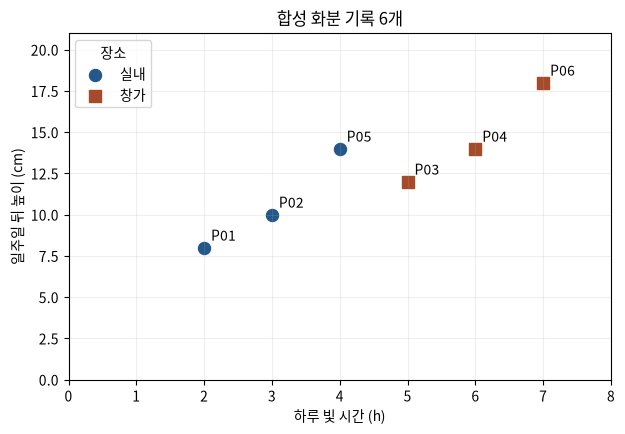

In [9]:
import matplotlib.pyplot as plt
from matplotlib import font_manager

%matplotlib inline
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ["Noto Sans CJK KR", "NanumGothic", "AppleGothic", "Malgun Gothic"]:
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(7, 4.5))
for place, marker, color in [("실내", "o", "#24578A"), ("창가", "s", "#A64B2A")]:
    group = plants.loc[plants["place"] == place]
    ax.scatter(group["light_h"], group["height_cm"],
               marker=marker, color=color, s=75, label=place)
for row in plants.itertuples(index=False):
    ax.annotate(row.pot_id, (row.light_h, row.height_cm),
                xytext=(5, 5), textcoords="offset points")
ax.set(title="합성 화분 기록 6개", xlabel="하루 빛 시간 (h)",
       ylabel="일주일 뒤 높이 (cm)", xlim=(0, 8), ylim=(0, 21))
ax.grid(alpha=0.2)
ax.legend(title="장소")
plt.show()


## 5. 정한 식과 배운 모델은 다릅니다

### 먼저 고정식을 계산하기

높이 예측을 설명하려고 임의로 다음 식을 정해 봅니다.

**예측 높이(cm) = 4 + 1 × 빛 시간(h) + 0.1 × 물(ml)**

1의 단위는 cm/h, 0.1의 단위는 cm/ml이므로 각 항은 cm입니다. P02에 넣으면 4+3+2=9cm입니다. 나중에 잰 높이는 10cm이므로 **실제 − 예측 = +1cm**입니다. 이 계수는 자료로 학습한 값도 실제 효과도 아닙니다. P03의 물은 미상이므로 빈칸을 어떤 값이라고 약속하지 않고서는 이 식을 바로 계산할 수 없습니다.

빛과 물을 순서대로 벡터 [3,20], 계수를 [1,0.1]로 놓으면 짝별 곱의 합이 내적입니다. 순서가 바뀌면 길이가 같아도 다른 계산이 됩니다.


In [10]:
p02 = plants.set_index("pot_id").loc["P02"]
p02_features = np.array([p02["light_h"], p02["water_ml"]], dtype=float)
fixed_weights = np.array([1.0, 0.1])
fixed_height = 4 + p02_features @ fixed_weights
print("P02의 고정식 예측(cm):", fixed_height)
print("실제 − 예측(cm):", p02["height_cm"] - fixed_height)
assert fixed_height == 9


P02의 고정식 예측(cm): 9.0
실제 − 예측(cm): 1.0


### 이제 질문을 바꾸어 작은 분류 모델을 학습하기

이번에는 높이 자체가 아니라 **높이가 12cm 이상인지**를 예측합니다. 나중에 잰 높이로 만든 0/1이 정답입니다. 이 두 질문의 출력 뜻과 단위가 다릅니다. P01~P04는 훈련, P05~P06은 별도 검증으로 정합니다. 서로 다른 화분이라고 가정합니다.

이 예의 입력으로 **물의 양과 방금 만든 노란 잎 수**를 고릅니다. 빛도 사용할 수 있지만 이번 모델에서는 쓰지 않습니다. 나중 높이·그 높이에서 만든 정답·연결용 ID는 모델 입력에 넣지 않습니다. 우선 훈련의 물 [0,20,결측,40] 중 관측한 값으로 평균 (0+20+40)÷3 = **20ml**를 배워 빈칸을 채웁니다. 전체 기록의 평균 24ml를 쓰면 검증 정보가 섞입니다.

물을 미리 정한 **10ml 단위**로 나타내면 20ml는 숫자 2입니다. 이것은 이 예에서 정한 기준이지 자료를 보고 찾은 최적값이 아닙니다. 두 입력은 순서대로 [물/10ml, 노란 잎 수]입니다. 각 행의 ID로 관찰을 찾아야 물과 잎 수가 같은 화분의 값이 됩니다.


In [11]:
from sklearn.impute import SimpleImputer
from sklearn.neighbors import NearestCentroid

training = plants.iloc[:4].copy()
validation = plants.iloc[4:].copy()
y_train = (training["height_cm"] >= 12).astype(int)
y_validation = (validation["height_cm"] >= 12).astype(int)

fill = SimpleImputer(strategy="mean")
train_water = fill.fit_transform(training[["water_ml"]]).ravel()
train_leaves = np.array([count_yellow_leaf(leaf_images[pot])
                         for pot in training["pot_id"]])
x_train = np.column_stack((train_water / 10, train_leaves))
print("훈련 ID:", training["pot_id"].tolist())
print("훈련에서 배운 물 대체값(ml):", fill.statistics_)
print("X = [물/10ml, 노란 잎 수]:\n", x_train)
print("X / y shape:", x_train.shape, "/", y_train.shape)
assert np.allclose(fill.statistics_, [20])
assert np.array_equal(x_train, [[0,0], [2,1], [2,2], [4,3]])


훈련 ID: ['P01', 'P02', 'P03', 'P04']
훈련에서 배운 물 대체값(ml): [20.]
X = [물/10ml, 노란 잎 수]:
 [[0. 0.]
 [2. 1.]
 [2. 2.]
 [4. 3.]]
X / y shape: (4, 2) / (4,)


### 평균은 왜 중심이 될까요?

정답이 0인 훈련 화분의 물은 0ml와 20ml입니다. 대표값 후보를 0·10·20ml로 놓으면, 각 값에서 후보를 뺀 뒤 제곱해 더한 값은 각각 **400·200·400ml²**입니다. 평균 10ml에서 가장 작습니다. 실제로 후보를 m이라 할 때

**(0−m)² + (20−m)² = 2(m−10)² + 200**

제곱은 0 이상이므로 10ml가 이 합을 가장 작게 합니다. 두 값의 분산은 가장 작은 합 200을 개수 2로 나눈 100ml²입니다. 이 성질 때문에 각 정답별 특성의 평균을 **중심**으로 쓰는 방법을 살펴봅니다. 이것이 모든 분류기의 최선이라는 뜻은 아닙니다.

각 정답 c와 입력 열 j에 대해 중심 μ(c,j)는 **그 정답인 훈련 행들의 j열 합 ÷ 그 행의 개수**입니다. 방금 만든 X에서 0의 중심은 [1, 0.5], 1의 중심은 [3, 2.5]입니다. 예를 들어 0의 첫 좌표는 (0+2)÷2=1입니다.

새 입력 x와 중심 μ의 **제곱거리**는 각 열의 차이를 제곱해 더한 Σ(j=1부터 2) (x(j)−μ(c,j))²입니다. 두 값이 음수가 아니므로 제곱근을 계산하지 않아도 어느 쪽이 가까운지 비교할 수 있습니다. 물/10ml와 잎 수를 같은 한 좌표씩 비교하는 선택은 두 특성의 상대적 영향에 영향을 줍니다. 기준을 다르게 정하면 예측이 달라질 수 있습니다. 다음은 여러 가능한 분류기 중 하나입니다.


In [12]:
model = NearestCentroid()
model.fit(x_train, y_train)
print("중심에 대응하는 정답:", model.classes_)
print("훈련에서 배운 두 특성의 중심:\n", model.centroids_)
assert np.allclose(model.centroids_, [[1, 0.5], [3, 2.5]])


중심에 대응하는 정답: [0 1]
훈련에서 배운 두 특성의 중심:
 [[1.  0.5]
 [3.  2.5]]


### 별도 검증에서 예측 확인

훈련에서 배운 20ml 대체값을 검증에 그대로 적용하고, 같은 ID의 잎 관찰을 찾고, **같은 열 순서와 10ml 기준**을 사용합니다. P05는 물 10ml·노란 잎 2개이므로 입력은 [1,2]입니다.

직접 구하면 0의 중심까지 제곱거리 (1−1)²+(2−0.5)²=**2.25**, 1의 중심까지 (1−3)²+(2−2.5)²=**4.25**입니다. 가까운 0을 예측하지만 P05의 나중 높이는 14cm이므로 실제 정답은 1입니다. P06도 확인해 **맞은 수 ÷ 검증 수**를 구하세요.


In [13]:
valid_water = fill.transform(validation[["water_ml"]]).ravel()
valid_leaves = np.array([count_yellow_leaf(leaf_images[pot])
                         for pot in validation["pot_id"]])
x_validation = np.column_stack((valid_water / 10, valid_leaves))
print("검증 X:", x_validation)
print("P05의 두 중심까지 제곱거리:",
      ((model.centroids_ - x_validation[0]) ** 2).sum(axis=1))
predictions = model.predict(x_validation)
result = pd.DataFrame({"pot_id": validation["pot_id"].to_numpy(),
                       "actual": y_validation.to_numpy(),
                       "prediction": predictions})
result["correct"] = result["actual"] == result["prediction"]
display(result)
validation_accuracy = result["correct"].sum() / len(result)
print("검증 정확도:", validation_accuracy)
assert predictions.tolist() == [0, 1] and validation_accuracy == 0.5


검증 X: [[1. 2.]
 [5. 3.]]
P05의 두 중심까지 제곱거리: [2.25 4.25]


,pot_id,actual,prediction,correct
0,P05,1,0,False
1,P06,1,1,True


검증 정확도: 0.5


검증 두 화분 중 한 개가 맞아 1/2입니다. 검증이 매우 작고 두 정답 모두 1이어서 현실 성능이나 다른 경우의 정확도를 추정할 수 없습니다. 검증은 모델·설정을 고르는 데 쓸 수 있지만 반복해 같은 검증만 보면 그 자료에 맞춰질 수 있습니다. 모든 선택을 마친 뒤의 **별도 최종 테스트**는 여기 제공하지 않습니다.

또한 [0,4]와 [1,3]은 평균이 모두 2이지만 분산은 각각 4와 1입니다. 중심 하나만 저장하면 퍼짐은 알 수 없습니다. 잎의 위치가 달라도 노란 잎 수와 물이 같으면 이 모델의 두 입력이 같아지므로 두 관찰을 구별하지 못합니다. 어떤 정보를 남길지는 문제에 따라 달라집니다.

훈련 P04의 물 40을 60으로 바꾼 복사본으로 새 대체값과 모델을 fit합니다. 원래 모델은 덮어쓰지 않습니다. **물 20ml·노란 잎 2개**의 예측이 달라질까요? 이 실험은 검증 점수로 두 모델을 고르는 단계가 아닙니다.


In [14]:
changed_training = training.copy()
changed_training.loc[changed_training["pot_id"] == "P04", "water_ml"] = 60
changed_fill = SimpleImputer(strategy="mean")
changed_water = changed_fill.fit_transform(changed_training[["water_ml"]]).ravel()
changed_leaves = np.array([count_yellow_leaf(leaf_images[pot])
                           for pot in changed_training["pot_id"]])
changed_x = np.column_stack((changed_water / 10, changed_leaves))
changed_model = NearestCentroid().fit(changed_x, y_train)
probe = np.array([[20 / 10, 2]])
original_prediction = int(model.predict(probe)[0])
changed_prediction = int(changed_model.predict(probe)[0])
print("같은 물 20ml·잎 2개의 원래 / 새 예측:", original_prediction, "/", changed_prediction)
print("원래 / 새 모델 중심:\n", model.centroids_, "\n", changed_model.centroids_)
assert (original_prediction, changed_prediction) == (1, 0)


같은 물 20ml·잎 2개의 원래 / 새 예측: 1 / 0
원래 / 새 모델 중심:
 [[1.  0.5]
 [3.  2.5]] 
 [[1.         0.5       ]
 [4.33333333 2.5       ]]


## 6. 결과를 ID에 붙여 다시 읽기

예측 숫자만 있으면 누구의 결과인지 알기 어렵습니다. 표를 읽은 직후 원래 ID 순서를 보관하고, 행을 정렬하거나 섞을 때 예측도 같은 ID와 함께 옮깁니다. 이 연습의 결과는 <code>pot_id,prediction</code> 헤더가 있는 CSV입니다. 먼저 디스크에 쓰지 않은 메모리 문자열로 만들고 다시 읽어 행 수·ID 순서·허용값을 확인합니다. 그다음 임시 폴더의 실제 파일에도 저장·재읽기합니다.


In [15]:
output = result[["pot_id", "prediction"]].copy()
required_order = validation["pot_id"].tolist()
shuffled = output.iloc[::-1]
restored = shuffled.set_index("pot_id").loc[required_order].reset_index()
output_csv = restored.to_csv(index=False, lineterminator="\n")
print("다시 읽을 CSV:\n" + output_csv)
checked = pd.read_csv(StringIO(output_csv))
assert checked["pot_id"].tolist() == required_order
assert len(checked) == len(validation) and set(checked["prediction"]).issubset({0, 1})


다시 읽을 CSV:
pot_id,prediction
P05,0
P06,1



### 실제 연습 파일도 확인하기

아래는 같은 결과를 임시 폴더의 <code>result.csv</code>에 쓰고 디스크에서 다시 읽습니다. 블록이 끝나면 연습 파일과 폴더는 자동으로 지워집니다. 실제로 제출해야 하는 과제라면 문제에서 요구한 작업 폴더와 파일명·형식을 확인하고, 자동 삭제되는 임시 파일 대신 그 위치에 저장해야 합니다.


In [16]:
import tempfile
from pathlib import Path

with tempfile.TemporaryDirectory(prefix="plant-result-") as directory:
    result_path = Path(directory) / "result.csv"
    restored.to_csv(result_path, index=False)
    file_check = pd.read_csv(result_path)
    print("파일에서 다시 읽은 ID:", file_check["pot_id"].tolist())
    assert file_check["pot_id"].tolist() == required_order
    assert file_check["prediction"].tolist() == restored["prediction"].tolist()
print("임시 파일은 정리됨:", not result_path.exists())
assert not result_path.exists()


파일에서 다시 읽은 ID: ['P05', 'P06']
임시 파일은 정리됨: True


## 7. 새로운 문제를 스스로 해결하기

**앞의 완성 예제를 가리고** 입력·정답·ID·시점·출력 조건을 먼저 적으세요. 아래 데이터는 새로운 합성 기기 문제입니다. 값의 뜻이 앞의 잎 관찰과 같다고 가정하지 마세요.

### 합성 기기 점검 명세

한 행은 기기 하나의 현재 관찰입니다. <code>unit</code>은 기기 결과를 찾는 이름이며, <code>signal</code>은 현재 측정값이고 0 또는 빈칸도 가능합니다. <code>panel</code>은 현재 상태를 담은 <code>(2,2,2)</code> 배열이며 축 순서는 행, 열, 채널입니다. **채널 0은 상태**(0=꺼짐, 1=켜짐), **채널 1은 대상**(0=배경, 2=센서)입니다. 배경의 상태 값은 의미가 없습니다. 이 숫자는 종류를 나타내며 숫자 차이가 센서 사이의 거리를 뜻하지 않습니다.

<code>label</code>은 나중에 확인한 <code>정상</code>, <code>점검</code>, <code>?</code> 중 하나이고 <code>?</code>는 미상입니다. 훈련 시에는 정답을 아는 행만 사용하고, 입력으로 쓸 빈 signal은 **알려진 훈련 행의 관측 평균**으로 채웁니다. 검증 정답은 모델을 정한 뒤 확인합니다. 새 기기의 정답은 주어지지 않습니다.

결과는 <code>sample_id,prediction</code> 헤더의 CSV입니다. 예측은 <code>정상</code> 또는 <code>점검</code>이며 요구 ID 순서는 **N7, N3, N1**입니다.

1. 어떤 항목이 언제 주어지는지, 목표·미상·연결용 ID를 적으세요. 학습에 쓸 ID, 관측 signal과 그 평균을 손으로 구하세요. 0과 빈칸은 어떻게 다른가요?
2. T2의 panel에서 <code>[0,1]</code>과 <code>[1,0]</code>의 뜻과 켜진 센서 수를 손으로 구하세요. 복사한 배열에서 배경의 상태만 바꾸거나 행과 열을 바꾸면 각각 무엇이 달라지나요? 코드로 확인하세요.
3. signal과 **panel에서 직접 만든 수치 특성 하나 이상**을 골라 의미·열 순서·shape를 적고, 타당한 학습 분류기를 스스로 선택해 알려진 훈련 행으로 fit하세요. 무엇을 배웠는지 값이나 구조로 설명하세요. 같은 수치 특성이라도 원래 관찰에서 잃을 수 있는 정보가 무엇인가요?
4. 별도 검증 예측·정확도를 구하고 작은 점수의 한계를 적으세요. 새로운 기기의 예측을 요구 순서의 CSV로 만들어 다시 읽고 헤더·행 수·ID·허용값을 검사하세요. 예측만 다른 순서로 옮기고 ID를 그대로 두면 왜 잘못될 수 있나요? 값이 우연히 같다면 겉으로 드러날까요?
5. signal **열 자체가 없거나** ID가 중복된 입력은 어떻게 알릴지 코드와 이유를 적으세요. 빈 값 한 칸을 대체하는 것과 구분하세요.

모델과 특성의 합리적인 선택은 하나만 있는 것이 아닙니다. 아래 입력 다음의 빈 칸에 직접 작성하고, 이유와 도움받은 내용을 남기세요.


In [17]:
panel_examples = {
    "A": np.array([[[0,2],[1,0]], [[0,2],[0,0]]]),
    "B": np.array([[[1,0],[1,2]], [[0,2],[0,0]]]),
    "C": np.array([[[1,2],[1,2]], [[0,2],[0,0]]]),
    "D": np.array([[[1,2],[1,2]], [[1,2],[0,0]]]),
}
exercise_train = pd.DataFrame([
    ("T1", 0.0, panel_examples["D"], "정상"),
    ("T2", 3.0, panel_examples["B"], "정상"),
    ("T3", np.nan, panel_examples["C"], "점검"),
    ("T4", 9.0, panel_examples["A"], "점검"),
    ("T5", 100.0, panel_examples["D"], "?"),
], columns=["unit", "signal", "panel", "label"])
exercise_validation = pd.DataFrame([
    ("V9", 3.0, panel_examples["D"], "정상"),
    ("V4", 8.0, panel_examples["A"], "점검"),
    ("V7", 4.0, panel_examples["D"], "점검"),
], columns=["unit", "signal", "panel", "label"])
exercise_input = pd.DataFrame([
    ("N3", 8.0, panel_examples["A"]),
    ("N1", 1.0, panel_examples["D"]),
    ("N7", 8.0, panel_examples["B"]),
], columns=["unit", "signal", "panel"])
exercise_order = ["N7", "N3", "N1"]
print("훈련 / 검증 / 새 기기 행 수:",
      len(exercise_train), len(exercise_validation), len(exercise_input))


훈련 / 검증 / 새 기기 행 수: 5 3 3


내가 정리한 항목의 역할·시점, 훈련 ID와 대체 평균:

T2의 축·범주와 직접 계산한 특성, 같은 값이 되는 다른 관찰:

선택한 입력 열·모델 / 배운 값 / 검증 예측과 정확도:

CSV의 ID 순서·내용 확인과 오류 처리:

실행 뒤 달라진 생각 / 받은 도움(없음·힌트·예시·직접 설명):


In [18]:
# 새 명세의 특성과 모델을 직접 선택해 작성하고 결과를 확인하세요.

## 8. 남은 필수 연습을 이어 하기

통합 경로에서 표·예측·학습을 연결했습니다. 다음의 다른 입력과 도구 연습은 아직 수행해야 합니다. 같은 설명을 처음부터 반복하기보다 안내된 준비 셀과 문제를 찾아 실행합니다.

### 기존 본문의 입력을 준비하기

1. 이 통합 노트북의 답을 저장하고 [기존 1주 본문](week01_python_tables.ipynb)을 **별도 새 커널**로 엽니다. 통합본의 <code>plants</code>를 그대로 쓰지 않습니다. 기존 표는 <code>sunlight_hours</code> 열을 쓰며 두 표의 일부 값도 다릅니다.
2. 기존 본문의 **‘노트북 사용하기’ 바로 아래 준비 코드**(<code>from pathlib import Path</code>로 시작)를 실행합니다. 이어 **‘7. CSV를 표로 읽기’ 바로 아래 CSV 코드**(<code>csv_text =</code>로 시작)를 실행해 원본 <code>plants</code>를 만듭니다. 마지막으로 **‘학습 확인 · 예제를 가리고 다시 하기’ 바로 아래 새 입력 코드**(<code>new_csv_text =</code>로 시작)를 실행해 <code>new_plants</code>와 B를 준비합니다. 전체 본문을 다시 실행할 필요는 없습니다.
3. 준비 후 아래 제목의 문제와 작성 칸을 찾습니다. 해당 절에 붙은 예제 코드가 필요하면 그 코드도 위에서 아래로 실행합니다.

- **필기·Python 진단:** ‘5. 필기 문제로 확인하기’, ‘6. Python에서 막히는 지점 찾기’의 진단과 traceback, ‘함수를 고쳐 새 입력에 적용하기’를 풉니다. 진단 확인 코드는 해당 문제 바로 뒤에 있습니다.
- **평균·분산의 원리:** ‘2. 평균은 합계를 같은 몫으로 나눈 값입니다’부터 ‘평균 계산을 순서로 적으면 알고리즘이 됩니다’까지 기호·평균·편차·분산을 확인합니다. ‘11. 손계산을 NumPy와 대조하기’에서 분산의 <code>ddof</code> 설명과 바로 아래 코드를 실행해 NumPy·pandas 기본 분모가 다를 수 있음을 살핍니다.
- **열 이름과 자료형:** ‘도움 없이 해 볼 작은 변경’의 코드로 만든 <code>dirty_plants</code>에서 P02의 <code>20ml</code>을 자료사전과 대조하고, 원본을 보존한 수정·평균을 직접 확인합니다. ‘학습 확인’의 새 배열·CSV·그래프 문제도 풉니다.
- **과제 A:** reshape와 전치가 같은 shape여도 값 배치가 다른 반례, 새 배열의 행별·열별 broadcasting과 오류를 작성합니다. 과제 안의 보정 예제 코드를 먼저 실행할 수 있습니다.
- **과제 B:** 새 수의 평균·분산과 단위를 계산하고 Matplotlib과 Seaborn을 각각 사용해 분포·범주를 그립니다. 그래프 예제 셀들을 위에서 아래로 실행하고, 겹친 점과 집계된 막대의 뜻을 구별합니다.
- **과제 C:** 앞에서 준비한 <code>new_plants</code>로 새 CSV의 열·자료형·결측을 확인하고 장소별 집계·병합을 합니다. 과제 C의 <code>site_notes</code> 코드도 실행하고 모르는 키·중복 키를 검사합니다.
- **과제 D·E:** 0과 미상을 구분해 개수·평균을 반환하는 함수를 만들고, 다른 순서의 수량·단가로 내적을 계산합니다. E의 코드도 실행한 뒤 새 세션에서 작성한 코드를 재실행합니다.

### 축·ID 교량의 필수 문제

[축·행렬·ID 교량](week01_axes_linear_bridge.ipynb)도 **별도 새 커널**로 열고 ‘1. 표를 숫자 배열로 옮기기’ 바로 아래 <code>import numpy as np</code>로 시작하는 준비 코드를 실행합니다. B에서 앞의 함수를 다시 쓰려면 ‘5. 질문과 후보의 벡터를 비교하고 실제 ID 찾기’ 아래 <code>query_ids =</code>로 시작하는 입력 코드와 이어지는 <code>def normalize_rows(vectors):</code>로 시작하는 함수 코드를 이 순서로 실행합니다. 함수 코드에는 앞 입력이 필요합니다. 실행한 다음 완성 예제를 가립니다. 직접 함수를 작성한다면 이 두 예제 코드를 대신 실행할 필요는 없습니다. ‘6. 낯선 입력으로 혼자 풀기’에서 필수 A와 B는 각각 <code>X_new =</code> 또는 <code>q_ids_new =</code>가 든 **입력 코드 셀을 실행한 뒤 빈 답안 셀에 직접 작성**합니다. 새 선형 변환과 검색 결과를 계산합니다. 검색 B에서는 원시 내적과 행별 길이·코사인을 비교하고 위치를 실제 ID로 돌려줍니다. 이 검색의 0벡터 정책은 위 화분 분류에 적용하지 않습니다. 막히면 앞의 해당 원리를 확인합니다. stack·lookup은 선택 교량입니다.

마지막에는 이 **통합 노트북**으로 돌아와 7절 기기 문제의 답·코드와 받은 도움을 저장하고, 위에서 아직 못 한 항목을 표시하세요. [문제 명세와 제출 형식](week01_problem_pipeline.ipynb)의 상세 오류·ZIP 예는 더 살펴볼 자료입니다. 이 상세 예나 통합본 실행만으로 위 필수 문제를 끝낸 것으로 표시하지 않습니다.

## 다음 학습으로 이어 보기

2주에는 이 훈련 전용 대체와 검증을 분할·지표로 넓히고, 3~5주에는 함수·손실·거리·분산을 다른 모델과 연결합니다. 6주에는 shape와 가중합이 신경망의 각 층에 이어지고, 7~9주에는 이미지·텍스트 표현과 검색에서도 원래 ID와 축을 확인합니다. 10주에는 처음 보는 명세의 입력·출력·제약을 다시 읽습니다. 이는 다음 학습을 위한 연결이며 후속 모델과 과제를 이미 완수했다는 뜻은 아닙니다.

## 9. 원문과 연습의 경계

[KOAI 2027 안내](https://kitpa.org/koai/2027)가 연결한 [국내 실라버스](https://kitpa.org/koai/syllabus)는 확인 당시 IOAI 2026 기준이라고 표시했습니다.

[IOAI 2025 Antique 국제 개인전 원문](https://raw.githubusercontent.com/IOAI-official/IOAI-2025/main/Individual-Contest/Antique/Antique.ipynb)은 5개 특성, 1=진품·−1=복제품·0=미상, 미상 표본까지 활용하는 과제와 무헤더 CSV 두 개를 포함한 ZIP 제출을 요구합니다. 위 화분·기기 예는 별도 합성 자료이고 알려진 라벨만 배우는 입문입니다. 이 노트북은 그 국제 과제 전체를 해결하거나 KOAI 2027의 실제 문제를 예측하지 않습니다.

[IOAI 2026 Robot Chasing 국제 개인전 원문](https://raw.githubusercontent.com/IOAI-official/IOAI-2026/e1963801aa4cf33a5a03520b39fa6620a7894c54/Individual-Contest/2_Robot_Chasing/statement.md)의 관찰은 (8,8,2) 배열 외에 로봇 번호·방향·문장 지시·들고 있는 물체를 포함합니다. 로봇마다 행동이 다를 수 있어 로봇 번호는 입력 단서가 될 수 있습니다. 행은 뒤섞인 독립 스냅샷으로, 이전 관찰·행동은 주어지지 않습니다. 출력은 입력과 같은 순서의 행동 코드 JSON입니다. 위의 (2,2,2) 잎·기기 격자는 별도 합성 연습이며 이 국제 문제 전체를 푼 것이 아닙니다.
